# RoadScan — bounded freezing pilot
Compare head-only, last-three-module and all-layer fine-tuning from identical saved road-damage weights. Use the same 2,400 training images, 400-image development monitor, four epochs, optimizer and augmentation. Evaluate all candidates and the unchanged checkpoint on both full development domains. This is a small, single-seed screening experiment, not proof of generalization or absence of overfitting. Notebook 09 performs the CPU data diagnosis first. Never open test labels. Keep the starting checkpoint if no pilot improves the declared development criterion.


## 1. Environment and saved plan
Use the prepared notebook 09 output and original dataset. Verify the starting checkpoint hash, exact module structure and fixed image counts. GPU is required for training; setup can run on CPU.


In [1]:
import sys, subprocess, json, shutil, hashlib, time, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
subprocess.run([sys.executable,'-m','pip','install','-q','--retries','2','--timeout','30','ultralytics==8.4.177'],check=True,timeout=180)
import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import display
OUT=Path('/kaggle/working/freeze_pilot');OUT.mkdir(exist_ok=True)
BASE=Path('/kaggle/input/notebooks/rimasabunasser/09-roadscan-data-diagnosis/diagnosis/freeze_inputs')
SOURCE=Path('/kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo')
assert (BASE/'plan.json').is_file(), 'Attach notebook 09 completed output.'
plan=json.loads((BASE/'plan.json').read_text())
CLASSES=['D00','D10','D20','D40']
START=BASE/'start.pt'
assert hashlib.sha256(START.read_bytes()).hexdigest()==plan['start_sha256']
probe=YOLO(str(START));modules=probe.model.model
assert len(modules)-1==plan['arms']['head_only'] and type(modules[-1]).__name__=='Detect'
assert list(probe.names.values())==CLASSES
print('Device available:',torch.cuda.is_available(),'| modules:',len(modules),flush=True)
display(pd.read_csv(BASE/'architecture.csv'))
shutil.copy2(BASE/'plan.json',OUT/'plan.json')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 182.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device available: True | modules: 24


,index,module,parameters
0,0,Conv,928
1,1,Conv,18560
2,2,C3k2,26080
3,3,Conv,147712
4,4,C3k2,103360
5,5,Conv,590336
6,6,C3k2,346112
7,7,Conv,1180672
8,8,C3k2,1380352
9,9,SPPF,656896


PosixPath('/kaggle/working/freeze_pilot/plan.json')

## 2. Cache only allowed training/development images
Rebase fixed manifests to the attached dataset. Copy each split into temporary local storage. Assert training/development path disjointness and save exact manifests and YAML files. Local caching reduces repeated remote reads. Temporary source images are excluded from notebook outputs.


In [2]:
LOCAL=Path('/kaggle/temp/freeze_pilot_data')
YAMLS={};tables={}
def rebase(p):return str(SOURCE/str(p).split('/RoadScan_yolo/',1)[1])
for split,filename in [('train','pilot_train_manifest'),('monitor','pilot_monitor_manifest'),('in_domain_dev','in_domain_dev_manifest'),('china_dev','china_dev_manifest')]:
    table=pd.read_csv(BASE/(filename+'.csv'));table['path']=table.path.map(rebase);table['label']=table.label.map(rebase);tables[split]=table
    images=LOCAL/split/'images';labels=LOCAL/split/'labels';images.mkdir(parents=True,exist_ok=True);labels.mkdir(exist_ok=True)
    def copy_pair(row):
        shutil.copy2(row.path,images/Path(row.path).name);shutil.copy2(row.label,labels/Path(row.label).name)
    with ThreadPoolExecutor(max_workers=8) as pool:list(pool.map(copy_pair,table.itertuples()))
    listing=OUT/(split+'.txt');listing.write_text('\n'.join(str(images/Path(p).name) for p in table.path))
    table.to_csv(OUT/(split+'_manifest.csv'),index=False)
    print('Cached:',split,len(table),flush=True)
assert [len(tables[s]) for s in tables]==[2400,400,1000,1977]
assert set(tables['train'].path).isdisjoint(set(tables['in_domain_dev'].path)|set(tables['china_dev'].path))
for split in ['monitor','in_domain_dev','china_dev']:
    path=OUT/(split+'.yaml');path.write_text(yaml.safe_dump(dict(path=str(LOCAL),train=str(OUT/'train.txt'),val=str(OUT/(split+'.txt')),names=dict(enumerate(CLASSES)))))
    YAMLS[split]=str(path)
print('Input preflight complete.',flush=True)


Cached: train 2400
Cached: monitor 400
Cached: in_domain_dev 1000
Cached: china_dev 1977
Input preflight complete.


## 3. Register identical training settings and a runtime budget
Freeze by actual top-level module indices, not an assumed layer number. Frozen modules also remain in evaluation mode during training so BatchNorm running statistics stay fixed. Train each arm for four epochs, selecting its best checkpoint on the identical monitor. A callback records actual trainable parameter counts and elapsed time. Stop at the end of an epoch if the 30-minute experiment budget is exceeded; incomplete arms are clearly flagged and cannot win. The budget excludes environment startup, caching and output saving.


In [3]:
assert torch.cuda.is_available(), 'Enable GPU only after notebook 09 diagnosis has been reviewed.'
common=dict(data=YAMLS['monitor'],epochs=plan['epochs'],patience=0,imgsz=640,batch=16,device=0,workers=2,seed=42,deterministic=True,
    optimizer='AdamW',lr0=0.0001,lrf=1.0,cos_lr=False,warmup_epochs=0.0,warmup_bias_lr=0.0,weight_decay=0.0005,
    mosaic=0.0,close_mosaic=0,mixup=0.0,copy_paste=0.0,fliplr=0.5,flipud=0.0,hsv_h=0.015,hsv_s=0.3,hsv_v=0.2,
    degrees=0.0,translate=0.05,scale=0.2,perspective=0.0,cache=False,amp=True,nms=True,save=True,save_period=-1,
    plots=True,project=str(OUT/'runs'),exist_ok=False)
(OUT/'training_settings.json').write_text(json.dumps(common,indent=2))
experiment_start=time.monotonic();deadline=experiment_start+plan['max_gpu_minutes']*60
training_rows=[];candidates={'unchanged':START};complete={'unchanged':True}
for name,freeze in plan['arms'].items():
    if time.monotonic()>deadline:
        print('Budget reached; remaining arms not started.',flush=True);break
    print('Starting arm:',name,'| freeze:',freeze,flush=True)
    detector=YOLO(str(START));arm_start=time.monotonic();epoch_times=[];parameter_count={}
    def preserve_frozen_statistics(trainer):
        if freeze is not None:
            for module in trainer.model.model[:freeze]:module.eval()
    def record_parameters(trainer):
        parameter_count['trainable']=sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
        parameter_count['total']=sum(p.numel() for p in trainer.model.parameters())
        print('Parameter counts:',parameter_count,flush=True)
    def record_epoch(trainer):
        epoch_times.append(time.monotonic()-arm_start)
        print('Completed epoch:',trainer.epoch+1,'| arm elapsed seconds:',round(epoch_times[-1],1),flush=True)
        if time.monotonic()>deadline:trainer.stop=True
    detector.add_callback('on_train_start',record_parameters)
    detector.add_callback('on_train_epoch_start',preserve_frozen_statistics)
    detector.add_callback('on_fit_epoch_end',record_epoch)
    detector.train(**common,freeze=freeze,name=name)
    run=Path(detector.trainer.save_dir);history=pd.read_csv(run/'results.csv');history.columns=history.columns.str.strip()
    completed=int(history.epoch.max())>=plan['epochs'];complete[name]=completed
    candidates[name]=run/'weights/best.pt'
    training_rows.append(dict(arm=name,freeze=freeze,epochs=int(history.epoch.max()),completed=completed,seconds=time.monotonic()-arm_start,**parameter_count))
    pd.DataFrame(training_rows).to_csv(OUT/'training_cost.csv',index=False)
    del detector;gc.collect();torch.cuda.empty_cache()
display(pd.DataFrame(training_rows))


Starting arm: head_only | freeze: 23
New https://pypi.org/project/ultralytics/8.4.178 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/freeze_pilot/monitor.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=23, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=1.0, mask_ratio=4, max_det=300, mi

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


        2/4      2.45G      1.594      1.313    0.01561         11        640: 100% ━━━━━━━━━━━━ 150/150 7.6it/s 19.8s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.0it/s 3.3s0.3s
                   all        400        715      0.455      0.382      0.377      0.164
Completed epoch: 2 | arm elapsed seconds: 81.8

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
        3/4      2.45G      1.573      1.317     0.0155         27        640: 100% ━━━━━━━━━━━━ 150/150 7.6it/s 19.8s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.6it/s 3.6s0.3s
                   all        400        715      0.452      0.374      0.375      0.164
Completed epoch: 3 | arm elapsed seconds: 105.6

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
        4/4      2.45G      1.582      1.274    0.01564      

,arm,freeze,epochs,completed,seconds,trainable,total
0,head_only,23.0,4,True,146.621739,934960,9950960
1,last_three_modules,21.0,4,True,111.519378,2778672,9950960
2,all_layers,NaN,4,True,168.155944,9950960,9950960


## 4. Evaluate the unchanged model and every pilot equally
Use 640 square padding, batch four, confidence floor 0.001, NMS IoU 0.70 and maximum 300 detections for every model on the unchanged full development domains. Selection uses worst-domain mAP50–95, then mean-domain mAP50–95. Keep incomplete arms out of ranking. These domains have been used for development; no blind-test claim is made. Save results after each evaluation.


In [4]:
rows=[];class_rows=[]
for name,checkpoint in candidates.items():
    for domain in ['in_domain_dev','china_dev']:
        if time.monotonic()>deadline and name!='unchanged':
            print('Budget reached; skipping remaining evaluations.',flush=True);break
        print('Evaluating:',name,domain,flush=True)
        detector=YOLO(str(checkpoint))
        metrics=detector.val(data=YAMLS[domain],imgsz=640,batch=4,device=0,workers=2,rect=False,conf=0.001,iou=0.7,max_det=300,nms=True,augment=False,plots=False,project=str(OUT/'evaluations'),name=f'{name}_{domain}')
        rows.append(dict(arm=name,domain=domain,completed=complete[name],mAP50=float(metrics.box.map50),mAP50_95=float(metrics.box.map),precision=float(metrics.box.mp),recall=float(metrics.box.mr)))
        for i,c in enumerate(metrics.box.ap_class_index):
            p,r,a50,a=metrics.box.class_result(i);class_rows.append(dict(arm=name,domain=domain,class_name=CLASSES[int(c)],precision=float(p),recall=float(r),AP50=float(a50),AP50_95=float(a)))
        pd.DataFrame(rows).to_csv(OUT/'domain_results.csv',index=False);pd.DataFrame(class_rows).to_csv(OUT/'class_results.csv',index=False)
        del detector,metrics;gc.collect();torch.cuda.empty_cache()
results=pd.DataFrame(rows)
rank=results[results.completed].groupby('arm').agg(domains=('domain','nunique'),worst_domain_AP=('mAP50_95','min'),mean_domain_AP=('mAP50_95','mean'),worst_domain_AP50=('mAP50','min'))
rank=rank[rank.domains==2].sort_values(['worst_domain_AP','mean_domain_AP'],ascending=False)
rank.to_csv(OUT/'ranking.csv');display(results);display(rank)
WINNER=rank.index[0]
print('Selected:',WINNER,flush=True)


Evaluating: unchanged in_domain_dev
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1341.6±405.4 MB/s, size: 62.2 KB)
val: Scanning /kaggle/temp/freeze_pilot_data/in_domain_dev/labels... 1000 images, 358 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.3Kit/s 0.7s0ss
val: New cache created: /kaggle/temp/freeze_pilot_data/in_domain_dev/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 20.8it/s 12.0s0.1s
                   all       1000       1260      0.584      0.457      0.486      0.225
                   D00        250        348      0.551      0.399      0.422      0.181
                   D10        153        250      0.463       0.34      0.357      0.137
                   D20        349        451      0.676      0.647      0

,arm,domain,completed,mAP50,mAP50_95,precision,recall
0,unchanged,in_domain_dev,True,0.485967,0.224765,0.584053,0.456908
1,unchanged,china_dev,True,0.244239,0.095103,0.334074,0.298092
2,head_only,in_domain_dev,True,0.492879,0.225455,0.579166,0.461155
3,head_only,china_dev,True,0.245604,0.096827,0.329472,0.301989
4,last_three_modules,in_domain_dev,True,0.490011,0.226032,0.603594,0.450502
5,last_three_modules,china_dev,True,0.246434,0.097406,0.325394,0.300835
6,all_layers,in_domain_dev,True,0.494317,0.229925,0.594249,0.466486
7,all_layers,china_dev,True,0.259186,0.106458,0.340680,0.309798


,domains,worst_domain_AP,mean_domain_AP,worst_domain_AP50
arm,,,,
all_layers,2,0.106458,0.168191,0.259186
last_three_modules,2,0.097406,0.161719,0.246434
head_only,2,0.096827,0.161141,0.245604
unchanged,2,0.095103,0.159934,0.244239


Selected: all_layers


## 5. Save all evidence and verify the selected checkpoint
Retain every candidate, training history, parameter count, timing and development result. Plot the loss/AP curves to examine short-run behavior. Test a fresh CPU load and save the checkpoint with exact inference settings. A four-epoch single-seed pilot cannot certify no overfitting; keep the unchanged model if it ranks first. Any improvement remains development-selected and needs a new local blind evaluation.


,arm,frozen_BN_buffers,max_absolute_change
0,head_only,156,0.0
1,last_three_modules,138,0.0


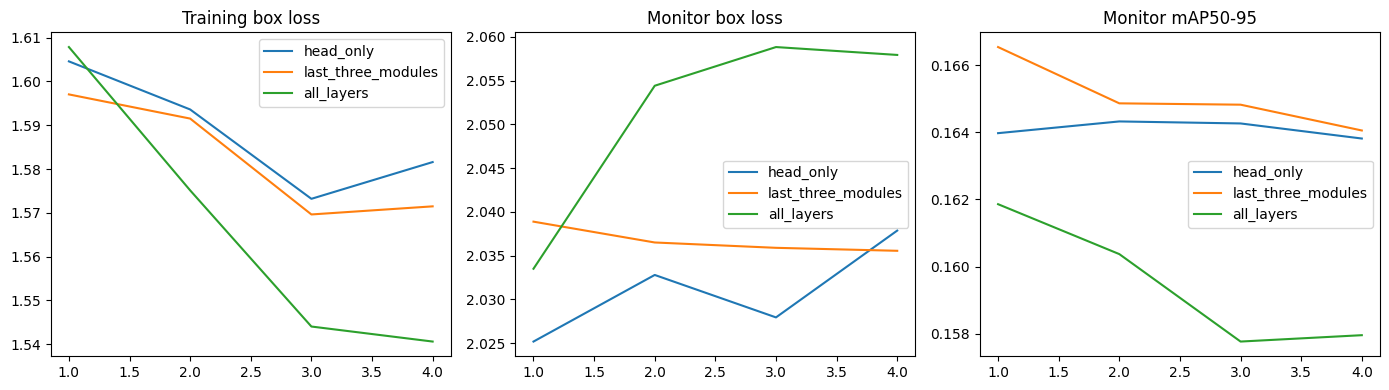

PILOT COMPLETE. Elapsed compute seconds: 773.1
# RoadScan freezing pilot

## Training cost

| arm                |   freeze |   epochs | completed   |   seconds |   trainable |   total |
|:-------------------|---------:|---------:|:------------|----------:|------------:|--------:|
| head_only          |       23 |        4 | True        |   146.622 |      934960 | 9950960 |
| last_three_modules |       21 |        4 | True        |   111.519 |     2778672 | 9950960 |
| all_layers         |      nan |        4 | True        |   168.156 |     9950960 | 9950960 |

## Development results

| arm                | domain        | completed   |    mAP50 |   mAP50_95 |   precision |   recall |
|:-------------------|:--------------|:------------|---------:|-----------:|------------:|---------:|
| unchanged          | in_domain_dev | True        | 0.485967 |  0.224765  |    0.584053 | 0.456908 |
| unchanged          | china_dev     | True        | 0.244239 |  0.0951034 |    0.334074 | 0.298092 |


,arm,best_monitor_epoch,monitor_AP
0,head_only,2,0.16433
1,last_three_modules,1,0.16655
2,all_layers,1,0.16186


## Review and next decision

The all-layer pilot ranks first on worst full-development-domain mAP50-95. Its China mAP50 is 25.9% versus 24.4% for the unchanged checkpoint; this is a modest development gain, not evidence of 92% performance or Saudi-road generalization.

The all-layer training curve shows falling training loss with rising monitor box loss and declining monitor AP after the first epoch. This supports short-run overfitting. Use the saved best-monitor checkpoint, never the last checkpoint by default. The checkpoint-selection table records the selected epoch for each arm. Freezing reduced the trainable parameter count but did not win this comparison.

Frozen BatchNorm statistics matched the starting checkpoint exactly in both frozen arms. The pilot ran four training epochs per arm. The framework also invokes the fit-epoch callback during final validation; any extra callback epoch in the console is not an extra training epoch. The authoritative epoch count comes from results.csv.

This is one small pilot with one seed and development reuse. Small gains may not reproduce. Do not claim zero overfitting. No test annotation was opened and no long extension is launched.

Next hypotheses, not completed experiments: training-only country/class sampling with explicit background control, then an isolated localization/crop experiment if warranted by the diagnostic contact sheets. Keep established development/test splits fixed. Obtain a new annotated local blind set before any deployment-quality claim.


FINAL PACKAGE VERIFIED. No further training is running.


In [6]:
# Verify that the frozen BatchNorm statistics were preserved in saved checkpoints.
reference_state = YOLO(str(START)).model.state_dict()
freeze_checks = []
for arm, frozen_count in plan['arms'].items():
    if frozen_count is None or arm not in candidates:
        continue
    current_state = YOLO(str(candidates[arm])).model.state_dict()
    prefixes = tuple(f'model.{i}.' for i in range(frozen_count))
    keys = [key for key in reference_state if key.startswith(prefixes)
            and (key.endswith('running_mean') or key.endswith('running_var'))]
    delta = max((float((reference_state[key].float()-current_state[key].float()).abs().max()) for key in keys), default=0.0)
    freeze_checks.append(dict(arm=arm, frozen_BN_buffers=len(keys), max_absolute_change=delta))
freeze_checks = pd.DataFrame(freeze_checks)
freeze_checks.to_csv(OUT/'frozen_statistics_check.csv', index=False)
display(freeze_checks)
assert (freeze_checks.max_absolute_change <= 0.001).all(), 'Frozen statistics changed; review the implementation.'
saved=OUT/'candidates';saved.mkdir(exist_ok=True)
for name,checkpoint in candidates.items():shutil.copy2(checkpoint,saved/(name+'.pt'))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for row in training_rows:
    h=pd.read_csv(OUT/'runs'/row['arm']/'results.csv');h.columns=h.columns.str.strip()
    axes[0].plot(h.epoch,h['train/box_loss'],label=row['arm']);axes[1].plot(h.epoch,h['val/box_loss'],label=row['arm']);axes[2].plot(h.epoch,h['metrics/mAP50-95(B)'],label=row['arm'])
for ax,title in zip(axes,['Training box loss','Monitor box loss','Monitor mAP50-95']):ax.set_title(title);ax.legend()
fig.tight_layout();fig.savefig(OUT/'pilot_curves.png',dpi=140);plt.show();plt.close(fig)
bundle=OUT/'model_bundle';bundle.mkdir(exist_ok=True);shutil.copy2(candidates[WINNER],bundle/'best.pt')
config=dict(classes=CLASSES,image_size=640,confidence=0.25,iou=0.7,max_det=300,rect=False,nms=True,arm=WINNER,threshold_note='Fixed diagnostic operating point; not a guaranteed deployment threshold.')
(bundle/'config.json').write_text(json.dumps(config,indent=2));(bundle/'requirements.txt').write_text('ultralytics==8.4.177\n')
(bundle/'predict.py').write_text("import argparse, json\nfrom pathlib import Path\nfrom ultralytics import YOLO\nparser=argparse.ArgumentParser()\nparser.add_argument('--image',required=True)\nparser.add_argument('--device',default='cpu')\nargs=parser.parse_args()\nroot=Path(__file__).resolve().parent\nc=json.loads((root/'config.json').read_text())\nmodel=YOLO(str(root/'best.pt'))\nmodel.predict(args.image,device=args.device,imgsz=c['image_size'],conf=c['confidence'],\n              iou=c['iou'],max_det=c['max_det'],rect=c['rect'],nms=c['nms'],save=True)\n")
check_code="from ultralytics import YOLO; m=YOLO("+repr(str(bundle/'best.pt'))+"); m.predict("+repr(str(tables['monitor'].iloc[0].path))+",device='cpu',imgsz=640,conf=.25,rect=False,nms=True,verbose=False); print('Fresh CPU load passed')"
fresh=subprocess.run([sys.executable,'-c',check_code],capture_output=True,text=True,timeout=180)
(OUT/'fresh_load.txt').write_text(fresh.stdout+fresh.stderr);assert fresh.returncode==0,fresh.stderr
report=['# RoadScan freezing pilot','## Training cost',pd.DataFrame(training_rows).to_markdown(index=False),'## Development results',results.to_markdown(index=False),'## Ranking',rank.to_markdown(),'Selected: '+WINNER,'## Interpretation','All arms share the starting checkpoint, training sample, augmentation, optimizer, seed and epoch budget. The monitor selects best checkpoints. Incomplete arms cannot win. The unchanged model is eligible.','This small single-seed pilot is development tuning, not proof of no overfitting or performance in Saudi Arabia. Test annotations were not opened. The 92% target is not guaranteed.','Frozen BatchNorm statistics were checked against the starting checkpoint. Fresh-process CPU inference passed.']
(OUT/'REPORT.md').write_text('\n\n'.join(report));(bundle/'MODEL_CARD.md').write_text('\n\n'.join(report))
(bundle/'SHA256.json').write_text(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in bundle.iterdir() if p.is_file() and p.name!='SHA256.json'},indent=2))
shutil.make_archive('/kaggle/working/roadscan_freeze_model','zip',root_dir=bundle)
print('PILOT COMPLETE. Elapsed compute seconds:',round(time.monotonic()-experiment_start,1),flush=True)
print('\n\n'.join(report))

selection_rows=[]
for item in training_rows:
    history=pd.read_csv(OUT/'runs'/item['arm']/'results.csv')
    history.columns=history.columns.str.strip()
    best_row=history.loc[history['metrics/mAP50-95(B)'].idxmax()]
    selection_rows.append(dict(arm=item['arm'],best_monitor_epoch=int(best_row.epoch),monitor_AP=float(best_row['metrics/mAP50-95(B)'])))
selection_table=pd.DataFrame(selection_rows)
selection_table.to_csv(OUT/'checkpoint_selection.csv',index=False)
display(selection_table)
interpretation='''## Review and next decision

The all-layer pilot ranks first on worst full-development-domain mAP50-95. Its China mAP50 is 25.9% versus 24.4% for the unchanged checkpoint; this is a modest development gain, not evidence of 92% performance or Saudi-road generalization.

The all-layer training curve shows falling training loss with rising monitor box loss and declining monitor AP after the first epoch. This supports short-run overfitting. Use the saved best-monitor checkpoint, never the last checkpoint by default. The checkpoint-selection table records the selected epoch for each arm. Freezing reduced the trainable parameter count but did not win this comparison.

Frozen BatchNorm statistics matched the starting checkpoint exactly in both frozen arms. The pilot ran four training epochs per arm. The framework also invokes the fit-epoch callback during final validation; any extra callback epoch in the console is not an extra training epoch. The authoritative epoch count comes from results.csv.

This is one small pilot with one seed and development reuse. Small gains may not reproduce. Do not claim zero overfitting. No test annotation was opened and no long extension is launched.

Next hypotheses, not completed experiments: training-only country/class sampling with explicit background control, then an isolated localization/crop experiment if warranted by the diagnostic contact sheets. Keep established development/test splits fixed. Obtain a new annotated local blind set before any deployment-quality claim.
'''
with (OUT/'REPORT.md').open('a') as file:file.write('\n\n'+selection_table.to_markdown(index=False)+'\n\n'+interpretation)
(bundle/'MODEL_CARD.md').write_text((OUT/'REPORT.md').read_text())
(bundle/'SHA256.json').write_text(json.dumps({p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in bundle.iterdir() if p.is_file() and p.name!='SHA256.json'},indent=2))
for name,digest in json.loads((bundle/'SHA256.json').read_text()).items():assert hashlib.sha256((bundle/name).read_bytes()).hexdigest()==digest
shutil.make_archive('/kaggle/working/roadscan_freeze_model','zip',root_dir=bundle)
from IPython.display import Markdown
display(Markdown(interpretation))
print('FINAL PACKAGE VERIFIED. No further training is running.')
